# exp04: Representasi Fitur

Membandingkan original, clean, penggabungan EAR, HRV absolut, rasio HRV, serta transformasi log HRV. Clean menghapus blink_count, iris_size_delta_std, dan eye_state_other_ratio. Logistic Regression juga membandingkan StandardScaler dengan RobustScaler. Tidak ada tuning parameter model.

Dataset: good_acceptable, window 15 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp04"
WINDOW = "window_15s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_15s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,732
1,Medium,1105
2,High,1174


,id,model,scaler,tune,variant,candidate_count
0,xgboost_original,xgboost,NaN,False,original,1
1,xgboost_clean,xgboost,NaN,False,clean,1
2,xgboost_ear,xgboost,NaN,False,ear,1
3,xgboost_absolute,xgboost,NaN,False,absolute,1
4,xgboost_ratio,xgboost,NaN,False,ratio,1
5,xgboost_log,xgboost,NaN,False,log,1
6,logistic_original,logistic,standard,False,original,1
7,logistic_clean,logistic,standard,False,clean,1
8,logistic_ear,logistic,standard,False,ear,1
9,logistic_absolute,logistic,standard,False,absolute,1


3011 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2698,313,3
1,fold_01,Andreas,2825,186,3
2,fold_02,Athaya,2755,256,3
3,fold_03,Fabian,2708,303,3
4,fold_04,Rafi,2691,320,3
5,fold_05,Savitri,2724,287,3
6,fold_06,Shakilla,2897,114,3
7,fold_07,Tio,2741,270,3
8,fold_08,faqih,2718,293,3
9,fold_09,ikhsan,2792,219,3


Complete run verified: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_15s_step_5s\full_d5b43f6b5ec5


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_15s_step_5s\full_d5b43f6b5ec5


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
0,logistic_absolute,0.361010,0.362633,0.357107,3011
6,logistic_ratio,0.353371,0.353325,0.348430,3011
1,logistic_clean,0.334108,0.342881,0.330682,3011
5,logistic_original,0.333776,0.342254,0.330316,3011
2,logistic_clean_robust,0.332448,0.341201,0.329231,3011
4,logistic_log,0.329459,0.338421,0.327810,3011
7,xgboost_absolute,0.313849,0.314471,0.310147,3011
10,xgboost_log,0.303554,0.307029,0.301193,3011
8,xgboost_clean,0.303554,0.307029,0.301193,3011
11,xgboost_original,0.297908,0.301788,0.295333,3011


,scope,model,label,precision,recall,f1,support
0,pooled,logistic_absolute,Low,0.266733,0.364754,0.308136,732
1,pooled,logistic_absolute,Medium,0.430427,0.419910,0.425103,1105
2,pooled,logistic_absolute,High,0.381974,0.303237,0.338082,1174
42,pooled,logistic_clean,Low,0.255773,0.393443,0.310011,732
43,pooled,logistic_clean,Medium,0.399640,0.401810,0.400722,1105
44,pooled,logistic_clean,High,0.354005,0.233390,0.281314,1174
84,pooled,logistic_clean_robust,Low,0.254885,0.392077,0.308934,732
85,pooled,logistic_clean_robust,Medium,0.397285,0.397285,0.397285,1105
86,pooled,logistic_clean_robust,High,0.352564,0.234242,0.281474,1174
126,pooled,logistic_ear,Low,0.249584,0.409836,0.310238,732


accuracy                     balanced_accuracy  \
                            min    median       max               min   
model                                                                   
logistic_absolute      0.072464  0.355401  0.464912          0.079365   
logistic_clean         0.065217  0.355401  0.605263          0.070106   
logistic_clean_robust  0.065217  0.348432  0.570175          0.070106   
logistic_ear           0.017544  0.292593  0.468647          0.010204   
logistic_log           0.050725  0.334495  0.640351          0.058201   
logistic_original      0.065217  0.355401  0.605263          0.070106   
logistic_ratio         0.043478  0.375427  0.631579          0.048942   
xgboost_absolute       0.000000  0.363036  0.417969          0.000000   
xgboost_clean          0.000000  0.344086  0.425197          0.000000   
xgboost_ear            0.000000  0.320819  0.433071          0.000000   
xgboost_log            0.000000  0.344086  0.425197          0.000000   
xgboost_original       0.000000  0.334471  0.409449          0.000000   
xgboost_ratio          0.000000  0.318919  0.383275          0.000000   

                                           macro_f1                      
                         median       max       min    median       max  
model                                                                    
logistic_absolute      0.368349  0.465689  0.130341  0.285718  0.451064  
logistic_clean         0.359261  0.456321  0.123656  0.265190  0.431448  
logistic_clean_robust  0.359261  0.454966  0.123656  0.269846  0.432908  
logistic_ear           0.344424  0.450631  0.020000  0.189383  0.450899  
logistic_log           0.367482  0.438089  0.101587  0.262593  0.421965  
logistic_original      0.359261  0.454231  0.123656  0.258837  0.431277  
logistic_ratio         0.397260  0.471740  0.080802  0.316386  0.418605  
xgboost_absolute       0.334776  0.429130  0.000000  0.288127  0.394243  
xgboost_clean          0.374859  0.423445  0.000000  0.272897  0.423889  
xgboost_ear            0.349969  0.435656  0.000000  0.269152  0.436701  
xgboost_log            0.374859  0.423445  0.000000  0.272897  0.423889  
xgboost_original       0.363072  0.401068  0.000000  0.263090  0.405268  
xgboost_ratio          0.343158  0.389482  0.000000  0.243844  0.364058

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

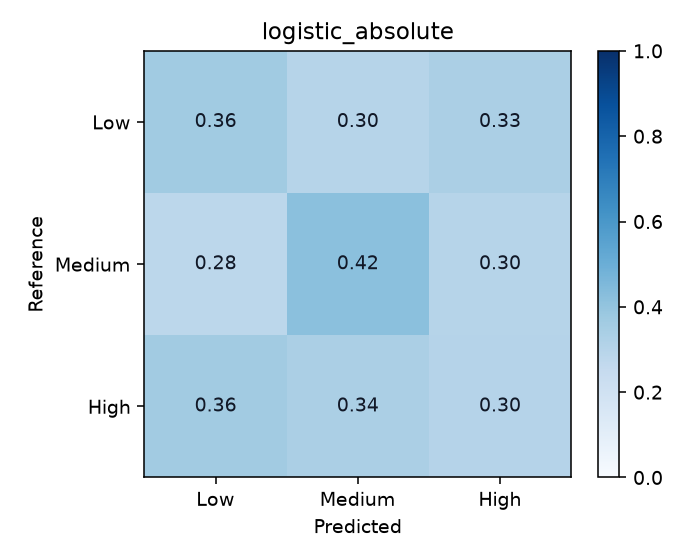

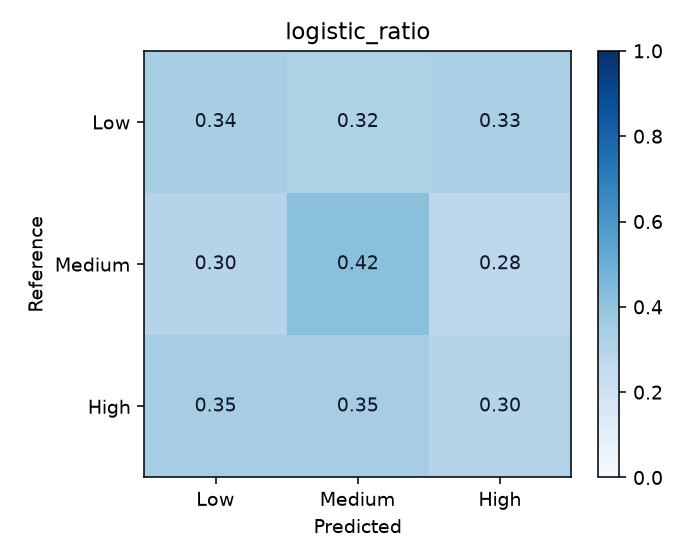

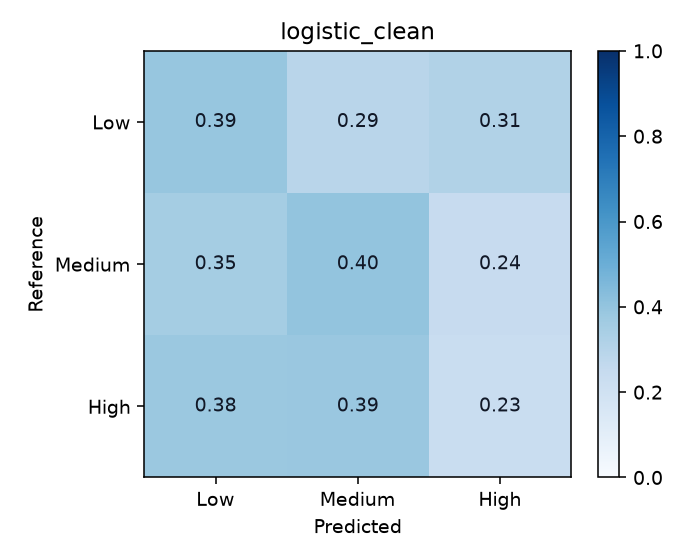

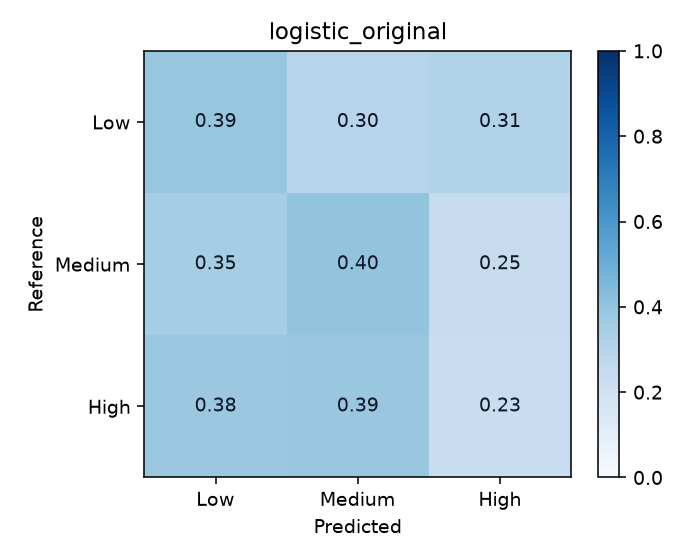

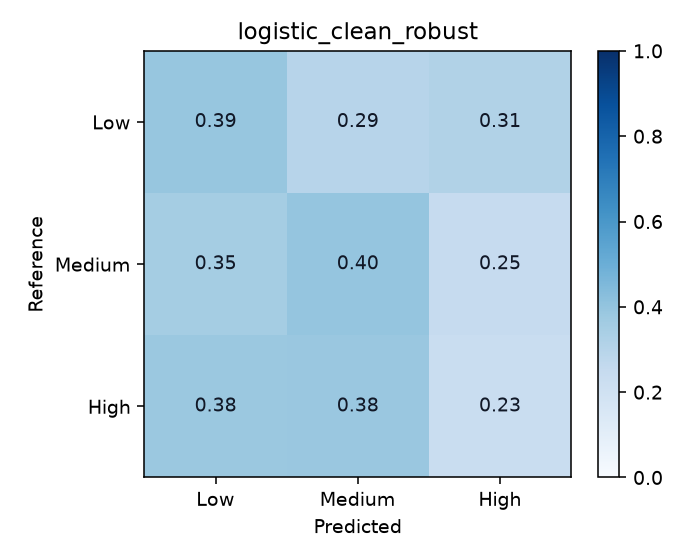

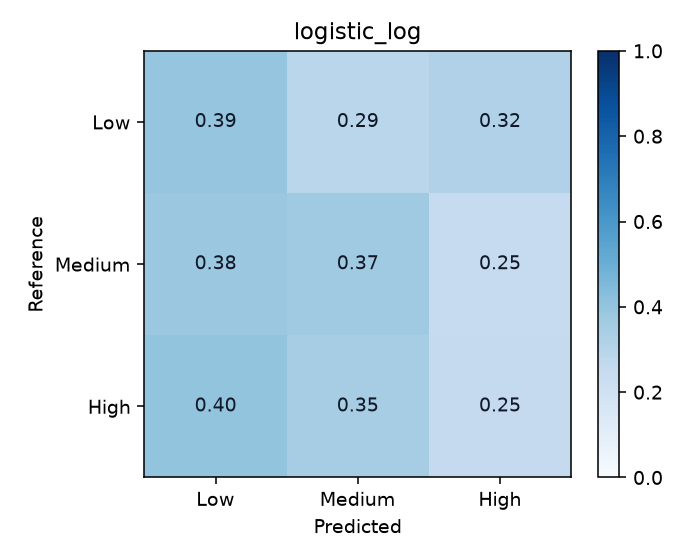

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_15s_step_5s\full_d5b43f6b5ec5
